In [16]:
from google.colab import files
import numpy as np
import matplotlib.pyplot as plt

# Waypoints in cm
X_ref = np.array([0, 25, 5, 40, 40, 65, 65, 40, 40, 65, 65])
Y_ref = np.array([0, 0, -40, -20, -40, -40, -20, -20, 0, 0, -20])


SIM_FILE  = 'gotogol_data_sim(2).txt'
REAL_FILE = 'gotogol_data_real.txt'

#Load the trajectory
def course_from_xy(x, y):
    course = np.zeros(len(x))                     # course_0 = 0: the robot starts facing +x
    for k in range(1, len(x)):
        dx, dy = x[k] - x[k-1], y[k] - y[k-1]
        if dx == 0 and dy == 0:                   # robot did not move: keep the course
            course[k] = course[k-1]
            continue
        c = np.arctan2(dy, dx)
        if abs((c - course[k-1] + np.pi) % (2 * np.pi) - np.pi) > np.pi / 2:
            c = c + np.pi                         # robot backing up: it faces the other way
        course[k] = course[k-1] + (c - course[k-1] + np.pi) % (2 * np.pi) - np.pi
    return course

x_s, y_s, t_s = np.loadtxt(SIM_FILE,  delimiter=',', unpack=True)
x_r, y_r, t_r = np.loadtxt(REAL_FILE, delimiter=',', unpack=True)

x_s, y_s = x_s * 100, y_s * 100                   # m -> cm

course_s = course_from_xy(x_s, y_s)
course_r = course_from_xy(x_r, y_r)

In [17]:
#distance and courseAngle segments
course_ref = np.arctan2(np.diff(Y_ref), np.diff(X_ref))      # course_ref[i-1] = course of segment i

def dist_to_segment(x, y, i):
    ax, ay, bx, by = X_ref[i-1], Y_ref[i-1], X_ref[i], Y_ref[i]
    u = ((x - ax) * (bx - ax) + (y - ay) * (by - ay)) / ((bx - ax)**2 + (by - ay)**2)
    u = min(max(u, 0), 1)
    return np.hypot(x - ax - u * (bx - ax), y - ay - u * (by - ay))

def errors(x, y, course):
    distance = np.zeros(len(x))
    courseAngle = np.zeros(len(x))
    i = 1
    for k in range(len(x)):
        if i < len(X_ref) - 1 and dist_to_segment(x[k], y[k], i + 1) < dist_to_segment(x[k], y[k], i):
            i += 1
        c = course_ref[i-1]
        distance[k] = -(x[k] - X_ref[i-1]) * np.sin(c) + (y[k] - Y_ref[i-1]) * np.cos(c)
        courseAngle[k] = (np.degrees(c - course[k]) + 180) % 360 - 180      # wrapped to [-180, 180)
    return distance, courseAngle

d_s, ca_s = errors(x_s, y_s, course_s)
d_r, ca_r = errors(x_r, y_r, course_r)

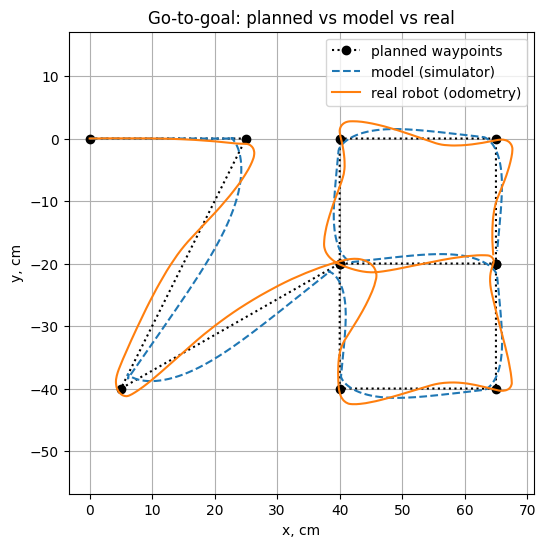

In [18]:
# 1. Planned path vs simulated vs real
plt.figure(figsize=(6, 6))
plt.plot(wp[:, 0], wp[:, 1], 'k:o', label='planned waypoints')
plt.plot(x_s, y_s, '--', label='model (simulator)')
plt.plot(x_r, y_r,       label='real robot (odometry)')
plt.axis('equal'); plt.grid(True); plt.legend()
plt.xlabel('x, cm'); plt.ylabel('y, cm')
plt.title('Go-to-goal: planned vs model vs real')
plt.show()

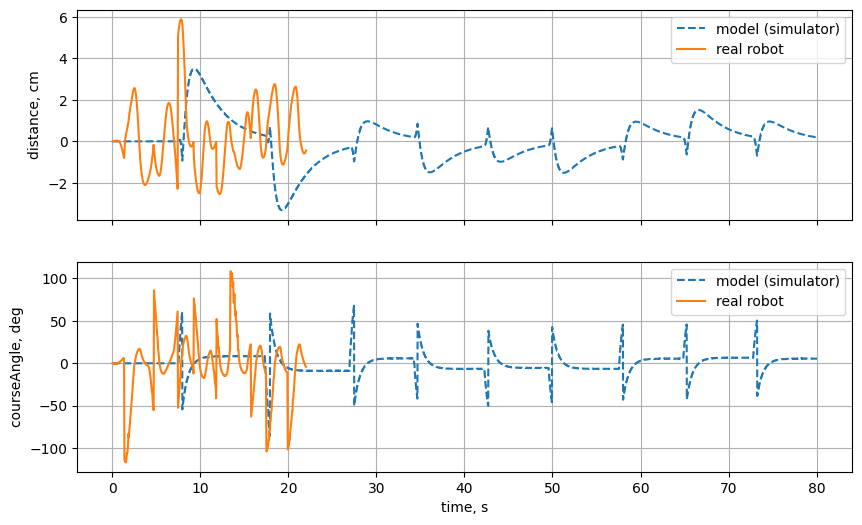

In [19]:
# 2. distance(t) and courseAngle(t)
fig, ax = plt.subplots(2, 1, figsize=(10, 6), sharex=True)
ax[0].plot(t_s / 1000, d_s, '--', label='model (simulator)')
ax[0].plot(t_r / 1000, d_r,       label='real robot')
ax[0].set_ylabel('distance, cm'); ax[0].grid(True); ax[0].legend()
ax[1].plot(t_s / 1000, ca_s, '--', label='model (simulator)')
ax[1].plot(t_r / 1000, ca_r,       label='real robot')
ax[1].set_ylabel('courseAngle, deg'); ax[1].set_xlabel('time, s'); ax[1].grid(True); ax[1].legend()
plt.show()

In [20]:
# 3. Waypoint miss: smallest distance between the trajectory and each waypoint
def waypoint_miss(x, y):
    return np.array([np.min(np.hypot(x - px, y - py)) for px, py in zip(X_ref, Y_ref)])

miss_s = waypoint_miss(x_s, y_s)
miss_r = waypoint_miss(x_r, y_r)
for i in range(len(X_ref)):
    print(f'Waypoint {i:2d} ({X_ref[i]:3d}, {Y_ref[i]:3d}): sim {miss_s[i]:5.1f} cm | real {miss_r[i]:5.1f} cm')

Waypoint  0 (  0,   0): sim   0.0 cm | real   0.0 cm
Waypoint  1 ( 25,   0): sim   1.8 cm | real   0.8 cm
Waypoint  2 (  5, -40): sim   2.0 cm | real   0.6 cm
Waypoint  3 ( 40, -20): sim   1.3 cm | real   0.2 cm
Waypoint  4 ( 40, -40): sim   1.2 cm | real   0.2 cm
Waypoint  5 ( 65, -40): sim   1.0 cm | real   0.3 cm
Waypoint  6 ( 65, -20): sim   0.9 cm | real   0.4 cm
Waypoint  7 ( 40, -20): sim   1.3 cm | real   0.2 cm
Waypoint  8 ( 40,   0): sim   0.9 cm | real   0.2 cm
Waypoint  9 ( 65,   0): sim   1.0 cm | real   0.3 cm
Waypoint 10 ( 65, -20): sim   0.9 cm | real   0.4 cm


In [21]:
# 4. Summary for each run
def summary(name, x, y, d, ca, t):
    print(f'{name}:')
    print(f'  max |distance|          = {np.max(np.abs(d)):6.2f} cm')
    print(f'  RMS distance            = {np.sqrt(np.mean(d**2)):6.2f} cm')
    print(f'  mean |courseAngle|      = {np.mean(np.abs(ca)):6.2f} deg')
    print(f'  final error to waypoint = {np.hypot(x[-1] - X_ref[-1], y[-1] - Y_ref[-1]):6.2f} cm')
    print(f'  run time                = {(t[-1] - t[0]) / 1000:6.1f} s')

summary('Simulator', x_s, y_s, d_s, ca_s, t_s)
summary('Real robot', x_r, y_r, d_r, ca_r, t_r)

Simulator:
  max |distance|          =   3.50 cm
  RMS distance            =   1.07 cm
  mean |courseAngle|      =   8.33 deg
  final error to waypoint =   2.00 cm
  run time                =   80.0 s
Real robot:
  max |distance|          =   5.88 cm
  RMS distance            =   1.66 cm
  mean |courseAngle|      =  24.28 deg
  final error to waypoint =   1.54 cm
  run time                =   22.0 s
